# A/B-тест SMS-рассылки X5: катить или нет

**Вопрос бизнеса:** увеличивает ли SMS-рассылка долю клиентов, которые совершают покупку,
стоит ли её масштабировать и на кого направлять в первую очередь.

**Данные:** [X5 Retail Hero](https://ods.ai/competitions/x5-retailhero-uplift-modeling) —
открытые данные эксперимента торговой сети X5. 200 039 клиентов случайно разделены на две группы:
одной отправили SMS, другой нет. Метрика `target` — совершил ли клиент покупку в период после
коммуникации. История покупок до кампании (8 млн чеков) используется для проверки сплита и CUPED.

In [1]:
import sys

sys.path.append("..")  # модули проекта: src/ и scripts/

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

from src import style
from src.ab import (
    bootstrap_diff_ci,
    cuped,
    diff_proportions,
    mde_proportions,
    segment_effects,
    srm_pvalue,
)
from src.style import num, pct, pvalue

style.apply()
pd.set_option("display.float_format", lambda x: num(x, 3))
DOCS = "../docs"

In [2]:
exp = pd.read_csv("../data/raw/uplift_train.csv")
clients = pd.read_csv("../data/raw/clients.csv")
checks = pd.read_parquet(
    "../data/interim/checks.parquet", columns=["client_id", "ts", "purchase_sum"]
)

last_ts = checks["ts"].max()
pre = checks.groupby("client_id").agg(
    checks_before=("ts", "size"), spend_before=("purchase_sum", "sum")
)
recent = (
    checks[checks["ts"] > last_ts - pd.Timedelta(days=28)]
    .groupby("client_id")
    .size()
    .rename("checks_28d")
)

df = (
    exp.merge(clients[["client_id", "age", "gender"]], on="client_id", how="left")
    .join(pre, on="client_id")
    .join(recent, on="client_id")
)
df[["checks_before", "spend_before", "checks_28d"]] = df[
    ["checks_before", "spend_before", "checks_28d"]
].fillna(0)
is_t = df["treatment_flg"] == 1

print(f"Клиентов: {num(len(df))}; с SMS: {num(is_t.sum())}; без SMS: {num((~is_t).sum())}")
print(f"Пропусков после объединения: {int(df[['age', 'gender']].isna().sum().sum())}")
print(f"Минимум покупок за 4 недели до кампании: {int(df['checks_28d'].min())}")

Клиентов: 200 039; с SMS: 99 981; без SMS: 100 058
Пропусков после объединения: 0
Минимум покупок за 4 недели до кампании: 1


**Важно про выборку.** У каждого клиента в эксперименте была хотя бы одна покупка за 4 недели
до кампании: в тест попали только активные клиенты. Поэтому выводы относятся к активной базе;
на «спящих» клиентах эффект может быть другим.

## 1. Корректен ли сплит

Прежде чем смотреть на эффект, проверяю, что группы сопоставимы: размер групп соответствует
плану 50/50 (SRM — sample ratio mismatch) и до кампании группы не отличались.

In [3]:
p_srm = srm_pvalue(is_t.sum(), (~is_t).sum())
print(f"Доля группы с SMS: {pct(is_t.mean(), 2)}; SRM p-value = {num(p_srm, 2)} — перекоса нет")

valid_age = df["age"].between(14, 100)
print(
    f"Возраст вне 14–100 лет (ошибки ввода): {num((~valid_age).sum())} клиентов — в балансе возраста не учитываются"
)
bal = df.assign(age=df["age"].where(valid_age))


def smd(col):
    a, b = bal.loc[is_t, col], bal.loc[~is_t, col]
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)


balance = pd.DataFrame(
    {
        "С SMS": bal[is_t][["age", "checks_before", "spend_before", "checks_28d"]].mean(),
        "Без SMS": bal[~is_t][["age", "checks_before", "spend_before", "checks_28d"]].mean(),
    }
)
balance["SMD"] = [smd(c) for c in balance.index]
balance.index = ["Возраст", "Чеков до кампании", "Выручка до кампании, ₽", "Чеков за 4 недели"]
balance

Доля группы с SMS: 49,98%; SRM p-value = 0,86 — перекоса нет
Возраст вне 14–100 лет (ошибки ввода): 883 клиентов — в балансе возраста не учитываются


,С SMS,Без SMS,SMD
Возраст,"46,465","46,378","0,005"
Чеков до кампании,"20,186","20,056","0,007"
"Выручка до кампании, ₽","8 625,658","8 569,273","0,006"
Чеков за 4 недели,"5,755","5,737","0,003"


In [4]:
gender = pd.crosstab(
    df["treatment_flg"].map({1: "С SMS", 0: "Без SMS"}), df["gender"], normalize="index"
)
gender.columns = gender.columns.map({"F": "женщины", "M": "мужчины", "U": "не указан"})
p_gender = stats.chi2_contingency(pd.crosstab(df["treatment_flg"], df["gender"]))[1]
print(f"Пол: хи-квадрат p-value = {num(p_gender, 2)}")
gender

Пол: хи-квадрат p-value = 0,77


gender,женщины,мужчины,не указан
treatment_flg,,,
Без SMS,"0,368","0,168","0,465"
С SMS,"0,369","0,167","0,464"


Стандартизированная разница средних (SMD) по всем признакам меньше 0,01 — группы сбалансированы
(порог, после которого стоит насторожиться, обычно 0,1). Доли по полу в группах совпадают до десятых
процента, хи-квадрат различий не находит.

## 2. Какой эффект тест мог заметить

Размер групп фиксирован, поэтому считаю минимальный обнаружимый эффект (MDE) при α = 0,05
и мощности 80%.

In [5]:
p_c = df.loc[~is_t, "target"].mean()
mde = mde_proportions(p_c, is_t.sum(), (~is_t).sum())
print(f"Доля купивших в контроле: {pct(p_c)}")
print(f"MDE: {num(mde * 100, 2)} п.п. — тест надёжно заметит прирост от {num(mde * 100, 1)} п.п.")

Доля купивших в контроле: 60,3%
MDE: 0,61 п.п. — тест надёжно заметит прирост от 0,6 п.п.


## 3. Результат

In [6]:
x_t, n_t = df.loc[is_t, "target"].sum(), is_t.sum()
x_c, n_c = df.loc[~is_t, "target"].sum(), (~is_t).sum()
res = diff_proportions(x_t, n_t, x_c, n_c)

boot = bootstrap_diff_ci(
    df.loc[is_t, "target"].values, df.loc[~is_t, "target"].values, n_boot=1000, seed=42
)

y_adj = cuped(df["target"].values, df["checks_before"].values)
cuped_diff = y_adj[is_t].mean() - y_adj[~is_t].mean()
se_cuped = np.sqrt(y_adj[is_t].var(ddof=1) / n_t + y_adj[~is_t].var(ddof=1) / n_c)
cuped_ci = (cuped_diff - 1.96 * se_cuped, cuped_diff + 1.96 * se_cuped)
var_cut = 1 - y_adj.var() / df["target"].var()

print(f"С SMS: {pct(res['p_t'])}, без SMS: {pct(res['p_c'])}")
print(
    f"Разница: +{num(res['diff'] * 100, 2)} п.п. (относительно +{pct(res['lift'])}), "
    f"95% ДИ [{num(res['ci_low'] * 100, 2)}; {num(res['ci_high'] * 100, 2)}] п.п., p {pvalue(res['p_value'])}"
)
print(f"Бутстрап, 95% ДИ: [{num(boot[0] * 100, 2)}; {num(boot[1] * 100, 2)}] п.п.")
print(
    f"CUPED по числу чеков до кампании: дисперсия −{pct(var_cut)}, "
    f"эффект +{num(cuped_diff * 100, 2)} п.п., 95% ДИ [{num(cuped_ci[0] * 100, 2)}; {num(cuped_ci[1] * 100, 2)}]"
)

С SMS: 63,7%, без SMS: 60,3%
Разница: +3,32 п.п. (относительно +5,5%), 95% ДИ [2,90; 3,75] п.п., p < 0,001
Бутстрап, 95% ДИ: [2,91; 3,74] п.п.
CUPED по числу чеков до кампании: дисперсия −12,7%, эффект +3,20 п.п., 95% ДИ [2,80; 3,59]


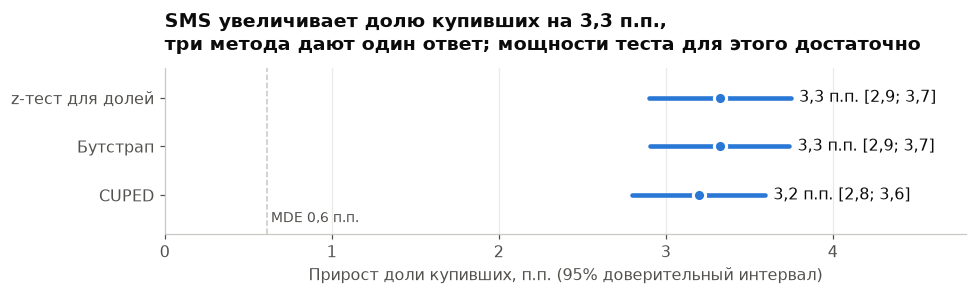

In [7]:
rows = [
    ("z-тест для долей", res["diff"], res["ci_low"], res["ci_high"]),
    ("Бутстрап", res["diff"], *boot),
    ("CUPED", cuped_diff, *cuped_ci),
]
fig, ax = plt.subplots(figsize=(9, 2.8))
for i, (_, est, lo, hi) in enumerate(rows):
    ax.plot([lo * 100, hi * 100], [i, i], color=style.ACCENT, linewidth=3, solid_capstyle="round")
    ax.plot(
        est * 100,
        i,
        "o",
        color=style.ACCENT,
        markersize=8,
        markeredgecolor="white",
        markeredgewidth=2,
    )
    ax.text(
        hi * 100 + 0.05,
        i,
        f"{num(est * 100, 1)} п.п. [{num(lo * 100, 1)}; {num(hi * 100, 1)}]",
        va="center",
        color=style.TEXT,
    )
ax.axvline(mde * 100, color=style.CONTEXT, linestyle="--", linewidth=1)
ax.text(mde * 100, 2.55, f" MDE {num(mde * 100, 1)} п.п.", color=style.MUTED, fontsize=9)
ax.set_yticks(range(len(rows)), [r[0] for r in rows])
ax.set_ylim(-0.6, 2.8)
ax.set_xlim(0, 4.8)
ax.invert_yaxis()
ax.set_xlabel("Прирост доли купивших, п.п. (95% доверительный интервал)")
ax.set_title(
    f"SMS увеличивает долю купивших на {num(res['diff'] * 100, 1)} п.п.,\n"
    "три метода дают один ответ; мощности теста для этого достаточно"
)
ax.grid(axis="y", visible=False)
style.finish(fig, f"{DOCS}/effect.png")
plt.show()

## 4. На кого SMS действует сильнее

Эффект в сегментах с поправкой Холма сразу на все 10 сравнений: чем больше сегментов
проверяешь, тем выше шанс случайно найти «значимый». Важно: у самых активных клиентов и без SMS
покупают 90%, поэтому прирост в процентных пунктах у них ограничен сверху — это не значит,
что SMS на них «не действует», но и денег рассылка на них приносит меньше.

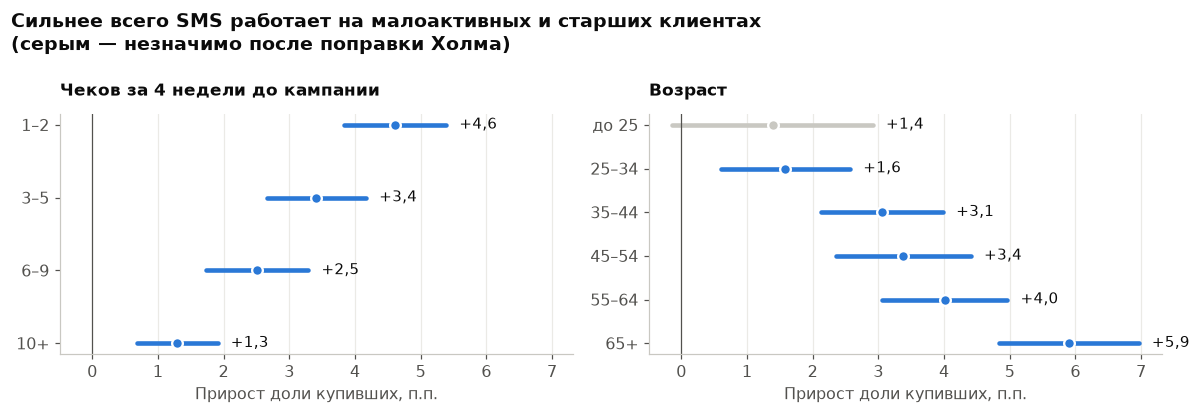

,Разрез,Сегмент,Клиентов,Без SMS,С SMS,Разница,ДИ от,ДИ до,p (Холм)
0,Активность,1–2,58553,"0,341","0,387","0,046","0,038","0,054","0,000"
1,Активность,3–5,64838,"0,577","0,611","0,034","0,027","0,042","0,000"
2,Активность,6–9,43088,"0,768","0,793","0,025","0,017","0,033","0,000"
3,Активность,10+,33560,"0,903","0,916","0,013","0,007","0,019","0,000"
0,Возраст,до 25,15958,"0,582","0,596","0,014","-0,001","0,029","0,074"
1,Возраст,25–34,38113,"0,585","0,601","0,016","0,006","0,026","0,003"
2,Возраст,35–44,42458,"0,593","0,623","0,031","0,021","0,040","0,000"
3,Возраст,45–54,34262,"0,597","0,631","0,034","0,023","0,044","0,000"
4,Возраст,55–64,38610,"0,619","0,659","0,040","0,031","0,050","0,000"
5,Возраст,65+,29755,"0,643","0,702","0,059","0,048","0,070","0,000"


In [8]:
df["activity"] = pd.cut(df["checks_28d"], [0, 2, 5, 9, np.inf], labels=["1–2", "3–5", "6–9", "10+"])
age_bins = [14, 25, 35, 45, 55, 65, 101]
age_labels = ["до 25", "25–34", "35–44", "45–54", "55–64", "65+"]
df["age_group"] = pd.cut(df["age"], age_bins, right=False, labels=age_labels)
df["age_group"] = df["age_group"].cat.add_categories("не указан").fillna("не указан")

by_activity = segment_effects(df, "activity")
by_age = segment_effects(df[df["age_group"] != "не указан"], "age_group")
# поправка Холма сразу по всем 10 сравнениям — строже, чем внутри каждого разреза
all_p = pd.concat([by_activity["p_value"], by_age["p_value"]], ignore_index=True)
holm_all = multipletests(all_p, method="holm")[1]
by_activity["p_holm"], by_age["p_holm"] = holm_all[: len(by_activity)], holm_all[len(by_activity) :]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, table, title in [
    (axes[0], by_activity, "Чеков за 4 недели до кампании"),
    (axes[1], by_age, "Возраст"),
]:
    for i, r in enumerate(table.itertuples()):
        significant = r.p_holm < 0.05
        color = style.ACCENT if significant else style.CONTEXT
        ax.plot(
            [r.ci_low * 100, r.ci_high * 100],
            [i, i],
            color=color,
            linewidth=3,
            solid_capstyle="round",
        )
        ax.plot(
            r.diff * 100,
            i,
            "o",
            color=color,
            markersize=7,
            markeredgecolor="white",
            markeredgewidth=1.5,
        )
        ax.text(
            r.ci_high * 100 + 0.2,
            i,
            f"+{num(r.diff * 100, 1)}",
            va="center",
            color=style.TEXT,
            fontsize=9.5,
        )
    ax.axvline(0, color=style.MUTED, linewidth=0.8)
    ax.set_yticks(range(len(table)), table["segment"].astype(str))
    ax.invert_yaxis()
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Прирост доли купивших, п.п.")
    ax.grid(axis="y", visible=False)
fig.suptitle(
    "Сильнее всего SMS работает на малоактивных и старших клиентах\n"
    "(серым — незначимо после поправки Холма)",
    x=0.01,
    ha="left",
    fontsize=12.5,
    fontweight="bold",
)
style.finish(fig, f"{DOCS}/segments.png")
plt.show()

cols = {
    "segment": "Сегмент",
    "n": "Клиентов",
    "p_c": "Без SMS",
    "p_t": "С SMS",
    "diff": "Разница",
    "ci_low": "ДИ от",
    "ci_high": "ДИ до",
    "p_holm": "p (Холм)",
}
pd.concat([by_activity.assign(Разрез="Активность"), by_age.assign(Разрез="Возраст")])[
    ["Разрез", *cols]
].rename(columns=cols)

## 5. Окупается ли рассылка

In [9]:
exp_checks = checks[checks["client_id"].isin(df["client_id"])]
avg_check = exp_checks["purchase_sum"].mean()
revenue_per_sms = res["diff"] * avg_check
print(f"Дополнительных покупателей на 1000 SMS: {num(res['diff'] * 1000, 0)}")
print(f"Средний чек клиентов эксперимента до кампании: {num(avg_check, 0)} ₽")
print(
    f"Дополнительная выручка на одно SMS (одна дополнительная покупка = один средний чек): "
    f"{num(revenue_per_sms, 1)} ₽"
)
segment_check = (
    exp_checks.merge(df[["client_id", "activity"]], on="client_id")
    .groupby("activity", observed=True)["purchase_sum"]
    .mean()
)
for r in by_activity.itertuples():
    print(
        f"  активность {r.segment}: средний чек {num(segment_check[r.segment], 0)} ₽, "
        f"выручка на SMS {num(r.diff * segment_check[r.segment], 1)} ₽"
    )

Дополнительных покупателей на 1000 SMS: 33
Средний чек клиентов эксперимента до кампании: 427 ₽
Дополнительная выручка на одно SMS (одна дополнительная покупка = один средний чек): 14,2 ₽


  активность 1–2: средний чек 522 ₽, выручка на SMS 24,1 ₽
  активность 3–5: средний чек 495 ₽, выручка на SMS 16,9 ₽
  активность 6–9: средний чек 441 ₽, выручка на SMS 11,1 ₽
  активность 10+: средний чек 348 ₽, выручка на SMS 4,5 ₽


## Решение

**Катить.** Эффект +3,3 п.п. (с 60,3% до 63,7% купивших) значим, тест имел достаточную мощность
(MDE 0,6 п.п.), а бутстрап и CUPED дают тот же ответ. Сплит корректен: перекоса групп нет,
до кампании группы не отличались.

**Окупаемость.** Каждые 1000 SMS дают около 33 дополнительных покупателей — примерно 14 ₽
дополнительной выручки на одно сообщение, если дополнительная покупка равна среднему чеку (427 ₽).
Рассылка окупается, если стоимость SMS ниже этой выручки, умноженной на маржу; маржу нужно взять
у финансов — в данных её нет.

**На кого направлять.** В первую очередь — на малоактивных клиентов (1–2 чека за месяц: +4,6 п.п.;
средний чек у них выше, поэтому около 24 ₽ выручки на SMS) и клиентов старше 55. У самых активных
(10+ чеков) 90% и так покупают: прирост +1,3 п.п. при меньшем среднем чеке — около 4,5 ₽ на SMS,
в 5 раз меньше. Их стоит исключить из рассылки, если SMS дороже. Различия между сегментами —
основание для следующего теста с таргетингом, а не доказанная причина.

**Ограничения.** В эксперимент попали только клиенты с покупкой за последние 4 недели: на спящих
клиентах эффект нужно проверять отдельно. Метрика бинарная — средний чек и частота покупок
после SMS в данных не измерены.